In [1]:
from tensorflow import keras
from keras.models import Model
from keras import layers
from keras.layers import Dense, Input, BatchNormalization, Activation
from keras.layers import Conv2D, SeparableConv2D, MaxPooling2D, GlobalAveragePooling2D, GlobalMaxPooling2D
#from keras.applications.imagenet_utils import _obtain_input_shape
#from keras.utils.data_utils import get_file
from sklearn.model_selection import KFold
from keras.datasets import mnist
from PIL import Image
# for creating a one hot vector for labels
#from keras.utils import np_utils
from IPython.display import display, Image
#import the models
from keras import Model
#add layers
from keras import layers
#add optimizer
from keras import optimizers
#add loss function 
from keras import losses
import random

import keras
import numpy as np
import pandas as pd 
import os
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
import tensorflow.keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import json
from skimage.metrics import structural_similarity as ssim

print("Hello world.")

Hello world.


In [2]:
x = []
label = []
x_validation = []
label_validation = []
x_test = []
image_test= []
label_test = []
mask_test = []
img_size = 224

test_range  = []
print("Hello world.")

Hello world.


In [3]:
def create_mask_from_json(json_file, height, width):

    # If file does not exist or is empty
    if not os.path.exists(json_file) or os.path.getsize(json_file) == 0:
        return np.zeros((height, width), dtype=np.uint8)

    with open(json_file, "r") as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError:
            return np.zeros((height, width), dtype=np.uint8)

    mask = np.zeros((height, width), dtype=np.uint8)

    for shape in data.get("shapes", []):
        pts = np.array(shape["points"], dtype=np.int32)
        pts = pts.reshape((-1, 1, 2))
        cv2.fillPoly(mask, [pts], 255)

    return mask

In [4]:
def apply_perturbations(images, perturbation):
   

    perturbed_images = []
    p_type = perturbation.get("type")

    for img in images:
        img_copy = img.copy()

        # ---------------- GAUSSIAN BLUR ----------------
        if p_type == 'gaussian_blur':
            k = perturbation.get('kernel_size', 5)
            if k % 2 == 0:
                k += 1
            img_copy = cv2.GaussianBlur(img_copy, (k, k), 0)

        # ---------------- NOISE ----------------
        elif p_type == 'noise':
            mean = perturbation.get('mean', 0)
            std = perturbation.get('std', 0.05)
            noise = np.random.normal(mean, std, img_copy.shape)
            img_copy = np.clip(img_copy + noise, 0, 1)

        # ---------------- BRIGHTNESS ----------------
        elif p_type == 'brightness':
            factor = perturbation.get('factor', 0.2)
            img_copy = np.clip(img_copy + factor, 0, 1)

        # ---------------- HUE SHIFT ----------------
        elif p_type == 'hue_shift':
            hsv = cv2.cvtColor((img_copy * 255).astype(np.uint8), cv2.COLOR_RGB2HSV)
            hsv[..., 0] = (hsv[..., 0] + perturbation.get('shift', 10)) % 180
            img_copy = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB).astype(np.float32) / 255.0

        # ---------------- CONTRAST ----------------
        elif p_type == 'contrast':
            factor = perturbation.get('factor', 1.0)
            mean = np.mean(img_copy, axis=(0, 1), keepdims=True)
            img_copy = np.clip((img_copy - mean) * factor + mean, 0, 1)

        # ---------------- GAMMA ----------------
        elif p_type == 'gamma':
            gamma = max(perturbation.get('gamma', 1.0), 1e-6)
            img_copy = np.clip(img_copy ** gamma, 0, 1)

        # ---------------- MOTION BLUR ----------------
        elif p_type == 'motion_blur':
            k = perturbation.get('kernel_size', 7)
            if k % 2 == 0:
                k += 1

            kernel = np.zeros((k, k))
            kernel[k // 2, :] = np.ones(k)
            kernel = kernel / k

            img_copy = cv2.filter2D(img_copy, -1, kernel)

        # ---------------- COMPRESSION ----------------
        elif p_type == 'compression':
            quality = perturbation.get('quality', 30)

            encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
            img_uint8 = (img_copy * 255).astype(np.uint8)

            _, encimg = cv2.imencode('.jpg', img_uint8, encode_param)
            decimg = cv2.imdecode(encimg, 1)

            img_copy = decimg.astype(np.float32) / 255.0

        # ---------------- OCCLUSION ----------------
        elif p_type == 'occlusion':
            size = perturbation.get('size', 0.2)
            h, w = img_copy.shape[:2]

            occ_h = int(h * size)
            occ_w = int(w * size)

            y = np.random.randint(0, h - occ_h)
            x = np.random.randint(0, w - occ_w)

            img_copy[y:y+occ_h, x:x+occ_w] = 0.0

        # ---------------- ERROR HANDLING ----------------
        else:
            raise ValueError(f"Unsupported perturbation type: {p_type}")

        perturbed_images.append(img_copy)

    return np.array(perturbed_images, dtype=np.float32)

In [5]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Azadirachta indica"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Azadirachta indica"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Azadirachta indica"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Azadirachta indica"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([0])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([0])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([0])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_8917.jpg   IMG_8917.json
IMG_8604.jpg   IMG_8604.json
IMG_8605.jpg   IMG_8605.json
IMG_8603.jpg   IMG_8603.json
IMG_8577.jpg   IMG_8577.json
IMG_8571.jpg   IMG_8571.json
IMG_8601.jpg   IMG_8601.json
IMG_8574.jpg   IMG_8574.json
IMG_8573.jpg   IMG_8573.json
IMG_8920.jpg   IMG_8920.json
IMG_8606.jpg   IMG_8606.json
IMG_8916.jpg   IMG_8916.json
IMG_8569.jpg   IMG_8569.json
IMG_8575.jpg   IMG_8575.json
IMG_8572.jpg   IMG_8572.json
IMG_8599.jpg   IMG_8599.json
IMG_8608.jpg   IMG_8608.json
IMG_8609.jpg   IMG_8609.json
IMG_8576.jpg   IMG_8576.json
IMG_8918.jpg   IMG_8918.json
144   41   20   20


In [6]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Calotropis gigantea"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Calotropis gigantea"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Calotropis gigantea"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Calotropis gigantea"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([1])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([1])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([1])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_9184.jpg   IMG_9184.json
IMG_9195.jpg   IMG_9195.json
IMG_9182.jpg   IMG_9182.json
IMG_9187.jpg   IMG_9187.json
IMG_9186.jpg   IMG_9186.json
IMG_9201.jpg   IMG_9201.json
IMG_9181.jpg   IMG_9181.json
IMG_9204.jpg   IMG_9204.json
IMG_9183.jpg   IMG_9183.json
IMG_9180.jpg   IMG_9180.json
IMG_9188.jpg   IMG_9188.json
IMG_9194.jpg   IMG_9194.json
IMG_9196.jpg   IMG_9196.json
IMG_9179.jpg   IMG_9179.json
IMG_9203.jpg   IMG_9203.json
IMG_9191.jpg   IMG_9191.json
IMG_9189.jpg   IMG_9189.json
IMG_9202.jpg   IMG_9202.json
IMG_9193.jpg   IMG_9193.json
IMG_9185.jpg   IMG_9185.json
IMG_9190.jpg   IMG_9190.json
313   84   41   41


In [7]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Centella asiatica"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Centella asiatica"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Centella asiatica"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Centella asiatica"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([2])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([2])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([2])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_4478.jpg   IMG_4478.json
IMG_0676.jpg   IMG_0676.json
IMG_0675.jpg   IMG_0675.json
IMG_0667.jpg   IMG_0667.json
IMG_4432.jpg   IMG_4432.json
IMG_4480.jpg   IMG_4480.json
IMG_4425.jpg   IMG_4425.json
IMG_4427.jpg   IMG_4427.json
IMG_0669.jpg   IMG_0669.json
IMG_4431.jpg   IMG_4431.json
IMG_0677.jpg   IMG_0677.json
IMG_0674.jpg   IMG_0674.json
IMG_4428.jpg   IMG_4428.json
IMG_0673.jpg   IMG_0673.json
IMG_4426.jpg   IMG_4426.json
IMG_4430.jpg   IMG_4430.json
IMG_4479.jpg   IMG_4479.json
IMG_4429.jpg   IMG_4429.json
IMG_4482.jpg   IMG_4482.json
IMG_0671.jpg   IMG_0671.json
454   124   61   61


In [8]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Hibiscus rosa-sinensis"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Hibiscus rosa-sinensis"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Hibiscus rosa-sinensis"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Hibiscus rosa-sinensis"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([3])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([3])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([3])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_8663.jpg   IMG_8663.json
IMG_8759.jpg   IMG_8759.json
IMG_8672.jpg   IMG_8672.json
IMG_8665.jpg   IMG_8665.json
IMG_8763.jpg   IMG_8763.json
IMG_8676.jpg   IMG_8676.json
IMG_8668.jpg   IMG_8668.json
IMG_8764.jpg   IMG_8764.json
IMG_8760.jpg   IMG_8760.json
IMG_8678.jpg   IMG_8678.json
IMG_8671.jpg   IMG_8671.json
IMG_8670.jpg   IMG_8670.json
IMG_8673.jpg   IMG_8673.json
IMG_8761.jpg   IMG_8761.json
IMG_8677.jpg   IMG_8677.json
IMG_8757.jpg   IMG_8757.json
IMG_8667.jpg   IMG_8667.json
IMG_8669.jpg   IMG_8669.json
IMG_8758.jpg   IMG_8758.json
IMG_8762.jpg   IMG_8762.json
IMG_8765.jpg   IMG_8765.json
604   167   82   82


In [9]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Justicia adhatoda"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Justicia adhatoda"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Justicia adhatoda"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Justicia adhatoda"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([4])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([4])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([4])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_0746.jpg   IMG_0746.json
IMG_0694.jpg   IMG_0694.json
IMG_0691.jpg   IMG_0691.json
IMG_0696.jpg   IMG_0696.json
IMG_0724.jpg   IMG_0724.json
IMG_0695.jpg   IMG_0695.json
IMG_0692.jpg   IMG_0692.json
IMG_0721.jpg   IMG_0721.json
IMG_0728.jpg   IMG_0728.json
IMG_0727.jpg   IMG_0727.json
IMG_0720.jpg   IMG_0720.json
IMG_0725.jpg   IMG_0725.json
IMG_0690.jpg   IMG_0690.json
IMG_0748.jpg   IMG_0748.json
IMG_0751.jpg   IMG_0751.json
IMG_0719.jpg   IMG_0719.json
IMG_0752.jpg   IMG_0752.json
IMG_0726.jpg   IMG_0726.json
IMG_0697.jpg   IMG_0697.json
IMG_0693.jpg   IMG_0693.json
744   207   102   102


In [10]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Kalanchoe pinnata"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Kalanchoe pinnata"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Kalanchoe pinnata"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Kalanchoe pinnata"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([5])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([5])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([5])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_1127.jpg   IMG_1127.json
IMG_1125.jpg   IMG_1125.json
IMG_1126.jpg   IMG_1126.json
IMG_1118.jpg   IMG_1118.json
IMG_1117.jpg   IMG_1117.json
IMG_1124.jpg   IMG_1124.json
IMG_1122.jpg   IMG_1122.json
IMG_1193.jpg   IMG_1193.json
IMG_1211.jpg   IMG_1211.json
IMG_1120.jpg   IMG_1120.json
IMG_1123.jpg   IMG_1123.json
IMG_1188.jpg   IMG_1188.json
IMG_1210.jpg   IMG_1210.json
IMG_1212.jpg   IMG_1212.json
IMG_1132.jpg   IMG_1132.json
IMG_1130.jpg   IMG_1130.json
IMG_1195.jpg   IMG_1195.json
IMG_1131.jpg   IMG_1131.json
IMG_1189.jpg   IMG_1189.json
IMG_1190.jpg   IMG_1190.json
IMG_1192.jpg   IMG_1192.json
IMG_1194.jpg   IMG_1194.json
IMG_1208.jpg   IMG_1208.json
904   253   125   125


In [11]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Mikania micrantha"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Mikania micrantha"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Mikania micrantha"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Mikania micrantha"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([6])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([6])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([6])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_1466.jpg   IMG_1466.json
IMG_1402.jpg   IMG_1402.json
IMG_0807.jpg   IMG_0807.json
IMG_1407.jpg   IMG_1407.json
IMG_0804.jpg   IMG_0804.json
IMG_0809.jpg   IMG_0809.json
IMG_1477.jpg   IMG_1477.json
IMG_0803.jpg   IMG_0803.json
IMG_0802.jpg   IMG_0802.json
IMG_1468.jpg   IMG_1468.json
IMG_1461.jpg   IMG_1461.json
IMG_1463.jpg   IMG_1463.json
IMG_0806.jpg   IMG_0806.json
IMG_0810.jpg   IMG_0810.json
IMG_1464.jpg   IMG_1464.json
IMG_1470.jpg   IMG_1470.json
IMG_1465.jpg   IMG_1465.json
IMG_1408.jpg   IMG_1408.json
IMG_1399.jpg   IMG_1399.json
IMG_1467.jpg   IMG_1467.json
IMG_0805.jpg   IMG_0805.json
1044   293   146   146


In [12]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Ocimum tenuiflorum"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Ocimum tenuiflorum"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Ocimum tenuiflorum"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Ocimum tenuiflorum"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([7])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([7])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([7])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_8657.jpg   IMG_8657.json
IMG_9010.jpg   IMG_9010.json
IMG_8622.jpg   IMG_8622.json
IMG_8627.jpg   IMG_8627.json
IMG_8621.jpg   IMG_8621.json
IMG_8628.jpg   IMG_8628.json
IMG_9013.jpg   IMG_9013.json
IMG_8629.jpg   IMG_8629.json
IMG_9011.jpg   IMG_9011.json
IMG_8618.jpg   IMG_8618.json
IMG_9012.jpg   IMG_9012.json
IMG_9009.jpg   IMG_9009.json
IMG_8625.jpg   IMG_8625.json
IMG_8620.jpg   IMG_8620.json
IMG_8658.jpg   IMG_8658.json
1150   323   161   161


In [13]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Phyllanthus emblica"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Phyllanthus emblica"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Phyllanthus emblica"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Phyllanthus emblica"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([8])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([8])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([8])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_1041.jpg   IMG_1041.json
IMG_1070.jpg   IMG_1070.json
IMG_1044.jpg   IMG_1044.json
IMG_1065.jpg   IMG_1065.json
IMG_1066.jpg   IMG_1066.json
IMG_1067.jpg   IMG_1067.json
IMG_1045.jpg   IMG_1045.json
IMG_1068.jpg   IMG_1068.json
IMG_1042.jpg   IMG_1042.json
IMG_1040.jpg   IMG_1040.json
IMG_1109.jpg   IMG_1109.json
IMG_1043.jpg   IMG_1043.json
IMG_1046.jpg   IMG_1046.json
IMG_1039.jpg   IMG_1039.json
IMG_1107.jpg   IMG_1107.json
IMG_1069.jpg   IMG_1069.json
IMG_1110.jpg   IMG_1110.json
IMG_1064.jpg   IMG_1064.json
IMG_1063.jpg   IMG_1063.json
IMG_1108.jpg   IMG_1108.json
1290   363   181   181


In [14]:
training = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Train/Terminalia arjuna"
validation = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Validation/Terminalia arjuna"
testing = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/BDMediLeaves Dataset Original - TrainValTest/BDMediLeaves Dataset Original - TrainValTest/Test/Terminalia arjuna"
json_folder = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/json_files/json_files/Terminalia arjuna"


images = os.listdir(training)
for i in images:
    image = cv2.imread(training +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x.append(image)
    label.append([9])

images = os.listdir(validation)
for i in images:
    image = cv2.imread(validation +'/'+ i) 
    if image is None:
       print(i)
       continue
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    x_validation.append(image)
    label_validation.append([9])

images = os.listdir(testing)
for i in images:
    image = cv2.imread(testing +'/'+ i) 
    if image is None:
       print(i)
       continue
        
    json_name = i.replace(".jpg", ".json")
    print(i," ", json_name)
    json_file = json_folder + '/' +json_name
    mask = create_mask_from_json( json_file , image.shape[0], image.shape[1])
    
    image = cv2.resize(image, (img_size, img_size))
    image = image.astype("float32") / 255.0
    mask = cv2.resize(mask, (img_size, img_size))
    x_test.append(image)
    label_test.append([9])
    mask_test.append(mask)




print(len(x)," ", len(x_validation)," ", len(x_test)," ",len(mask_test))

IMG_0873.jpg   IMG_0873.json
IMG_0874.jpg   IMG_0874.json
IMG_0824.jpg   IMG_0824.json
IMG_0876.jpg   IMG_0876.json
IMG_0829.jpg   IMG_0829.json
IMG_0836.jpg   IMG_0836.json
IMG_0879.jpg   IMG_0879.json
IMG_0881.jpg   IMG_0881.json
IMG_0878.jpg   IMG_0878.json
IMG_0833.jpg   IMG_0833.json
IMG_0831.jpg   IMG_0831.json
IMG_0877.jpg   IMG_0877.json
IMG_0872.jpg   IMG_0872.json
IMG_0818.jpg   IMG_0818.json
IMG_0825.jpg   IMG_0825.json
IMG_0827.jpg   IMG_0827.json
IMG_0880.jpg   IMG_0880.json
IMG_0832.jpg   IMG_0832.json
IMG_0820.jpg   IMG_0820.json
IMG_0823.jpg   IMG_0823.json
IMG_0834.jpg   IMG_0834.json
1440   406   202   202


In [15]:
x = np.asarray(x)
x_validation = np.asarray(x_validation)
x_test = np.asarray(x_test)

print(len(x)," ", len(x_validation)," ", len(x_test))

1440   406   202


In [16]:
from tensorflow.keras.utils import to_categorical 

label = np.array(label)
label = to_categorical(label , 10 )
print(len(label))



label_validation = np.array(label_validation)
label_validation = to_categorical(label_validation , 10 )
print(len(label_validation))

label_test = np.array(label_test)
label_test = to_categorical(label_test , 10 )
print(len(label_test))

1440
406
202


In [17]:
x_test_blur = apply_perturbations(x_test, {'type':'gaussian_blur','kernel_size':5})
x_test_noise = apply_perturbations(x_test, {'type':'noise','mean':0,'std':0.05})
x_test_brightness = apply_perturbations(x_test, {'type':'brightness','factor':0.2})
x_test_hue = apply_perturbations(x_test, {'type':'hue_shift','shift':15})
x_test_contrast = apply_perturbations(
    x_test,
    {'type': 'contrast', 'factor': 0.5}
)

x_test_gamma = apply_perturbations(
    x_test,
    {'type': 'gamma', 'gamma': 2.0}
)

x_test_motion_blur = apply_perturbations(
    x_test,
    {'type': 'motion_blur', 'kernel_size': 7}
)
# ---------------- COMPRESSION ----------------
x_test_compression = apply_perturbations(
    x_test,
    {'type': 'compression', 'quality': 30}   # lower = stronger compression
)

# ---------------- OCCLUSION ----------------
x_test_occlusion = apply_perturbations(
    x_test,
    {'type': 'occlusion', 'size': 0.2}   # 20% area blocked
)



x_test_blur = np.array(x_test_blur, dtype=np.float32)
x_test_noise = np.array(x_test_noise, dtype=np.float32)
x_test_brightness = np.array(x_test_brightness, dtype=np.float32)
x_test_hue = np.array(x_test_hue, dtype=np.float32)
x_test_contrast = np.array(x_test_contrast , dtype=np.float32)
x_test_gamma = np.array(x_test_gamma , dtype=np.float32)
x_test_motion_blur = np.array(x_test_motion_blur , dtype=np.float32)
x_test_compression = np.array(x_test_compression , dtype=np.float32)
x_test_occlusion = np.array(x_test_occlusion , dtype=np.float32)

print("Hello world.")

Hello world.


In [18]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense


model_path = "/kaggle/input/datasets/ragibmehedi/bdmedidataset/keras_files/keras_files/ResNet50_BDMediLeaves.keras"

model = keras.models.load_model(model_path) 

model.summary()

I0000 00:00:1783487741.835734      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783487741.838495      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,378,400 (93.00 MB)

 Trainable params: 263,562 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 527,126 (2.01 MB)

In [19]:
test_loss, test_accuracy = model.evaluate(x_test, label_test )
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

2/7 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.6094 - loss: 1.7363 

I0000 00:00:1783487759.056505     129 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 667ms/step - accuracy: 0.4604 - loss: 1.7277
Test Accuracy: 0.4604
Test Loss: 1.7277


In [20]:
test_loss_noise , test_accuracy_noise = model.evaluate(x_test_noise, label_test)
print(f"Test Accuracy noise: {test_accuracy_noise:.4f}")
print(f"Test Loss noise: {test_loss_noise:.4f}")

test_loss_blur , test_accuracy_blur = model.evaluate(x_test_blur, label_test)
print(f"Test Accuracy blur: {test_accuracy_blur:.4f}")
print(f"Test Loss blur: {test_loss_blur:.4f}")


test_loss_brightness , test_accuracy_brightness = model.evaluate(x_test_brightness, label_test)
print(f"Test Accuracy brightness: {test_accuracy_brightness:.4f}")
print(f"Test Loss brightness: {test_loss_brightness:.4f}")

test_loss_hue , test_accuracy_hue = model.evaluate(x_test_hue , label_test)
print(f"Test Accuracy hue: {test_accuracy_hue:.4f}")
print(f"Test Loss hue: {test_loss_hue:.4f}")

test_loss_contrast, test_accuracy_contrast = model.evaluate(x_test_contrast, label_test )
print(f"Test Accuracy contrast: {test_accuracy_contrast:.4f}")
print(f"Test Loss contrast: {test_loss_contrast:.4f}")

test_loss_gamma, test_accuracy_gamma = model.evaluate(x_test_gamma , label_test )
print(f"Test Accuracy gamma: {test_accuracy_gamma:.4f}")
print(f"Test Loss gamma: {test_loss_gamma:.4f}")

test_loss_motion_blur , test_accuracy_motion_blur = model.evaluate(x_test_motion_blur , label_test )
print(f"Test Accuracy blur: {test_accuracy_motion_blur:.4f}")
print(f"Test Loss blur: {test_loss_motion_blur:.4f}")

test_loss_compression, test_accuracy_compression = model.evaluate(x_test_compression, label_test )
print(f"Test Accuracy compression: {test_accuracy_compression:.4f}")
print(f"Test Loss compression: {test_loss_compression:.4f}")

test_loss_occlusion, test_accuracy_occlusion = model.evaluate(x_test_occlusion, label_test )
print(f"Test Accuracy occlusion: {test_accuracy_occlusion:.4f}")
print(f"Test Loss occlusion: {test_loss_occlusion:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.4406 - loss: 1.7507
Test Accuracy noise: 0.4406
Test Loss noise: 1.7507
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.1188 - loss: 2.2981
Test Accuracy blur: 0.1188
Test Loss blur: 2.2981
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.3713 - loss: 1.8608
Test Accuracy brightness: 0.3713
Test Loss brightness: 1.8608
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.4851 - loss: 1.7114
Test Accuracy hue: 0.4851
Test Loss hue: 1.7114
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.1139 - loss: 2.7081 
Test Accuracy contrast: 0.1139
Test Loss contrast: 2.7081
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.3713 - loss: 1.7682
Test Accuracy gamma: 0.3713
Test Loss gamma: 1.7682
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.1188 - loss: 2.4906
Test Accuracy blur: 0.1188
Test Loss blur: 2.4906
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.3911 - loss: 1.8145
Test Accuracy compression: 0.3911
Test Loss compres

In [21]:
accuracy_stability_noise = 1 - (abs(test_accuracy - test_accuracy_noise))/ (test_accuracy + test_accuracy_noise + 1e-8)
print(f"accuracy_stability_noise : {accuracy_stability_noise }")

accuracy_stability_blur = 1 - (abs(test_accuracy - test_accuracy_blur))/ (test_accuracy + test_accuracy_blur + 1e-8)
print(f"accuracy_stability_blur : {accuracy_stability_blur }")

accuracy_stability_brightness = 1 - (abs(test_accuracy - test_accuracy_brightness))/ (test_accuracy + test_accuracy_brightness + 1e-8)
print(f"accuracy_stability_brightness : {accuracy_stability_brightness }")

accuracy_stability_hue = 1 - (abs(test_accuracy - test_accuracy_hue))/ (test_accuracy + test_accuracy_hue + 1e-8)
print(f"accuracy_stability_hue : {accuracy_stability_hue }")

accuracy_stability_contrast = 1 - (abs(test_accuracy - test_accuracy_contrast))/ (test_accuracy + test_accuracy_contrast + 1e-8)
print(f"accuracy_stability_contrast : {accuracy_stability_contrast }")

accuracy_stability_gamma = 1 - (abs(test_accuracy - test_accuracy_gamma))/ (test_accuracy + test_accuracy_gamma + 1e-8)
print(f"accuracy_stability_gamma : {accuracy_stability_gamma }")

accuracy_stability_motion_blur = 1 - (abs(test_accuracy - test_accuracy_motion_blur))/ (test_accuracy + test_accuracy_motion_blur + 1e-8)
print(f"accuracy_stability_motion_blur : {accuracy_stability_motion_blur }")

accuracy_stability_compression = 1 - (abs(test_accuracy - test_accuracy_compression))/ (test_accuracy + test_accuracy_compression + 1e-8)
print(f"accuracy_stability_compression : {accuracy_stability_compression }")

accuracy_stability_occlusion = 1 - (abs(test_accuracy - test_accuracy_occlusion))/ (test_accuracy + test_accuracy_occlusion + 1e-8)
print(f"accuracy_stability_occlusion : {accuracy_stability_occlusion }")

accuracy_stability_noise : 0.9780219517313705
accuracy_stability_blur : 0.4102564171400014
accuracy_stability_brightness : 0.8928571428656316
accuracy_stability_hue : 0.9738219980566171
accuracy_stability_contrast : 0.396551735764727
accuracy_stability_gamma : 0.8928571428656316
accuracy_stability_motion_blur : 0.4102564171400014
accuracy_stability_compression : 0.9186046427581405
accuracy_stability_occlusion : 0.9248554809427691


In [22]:
for layer in model.layers:
    print( layer.name, layer.output.shape)

input_layer (None, 224, 224, 3)
conv1_pad (None, 230, 230, 3)
conv1_conv (None, 112, 112, 64)
conv1_bn (None, 112, 112, 64)
conv1_relu (None, 112, 112, 64)
pool1_pad (None, 114, 114, 64)
pool1_pool (None, 56, 56, 64)
conv2_block1_1_conv (None, 56, 56, 64)
conv2_block1_1_bn (None, 56, 56, 64)
conv2_block1_1_relu (None, 56, 56, 64)
conv2_block1_2_conv (None, 56, 56, 64)
conv2_block1_2_bn (None, 56, 56, 64)
conv2_block1_2_relu (None, 56, 56, 64)
conv2_block1_0_conv (None, 56, 56, 256)
conv2_block1_3_conv (None, 56, 56, 256)
conv2_block1_0_bn (None, 56, 56, 256)
conv2_block1_3_bn (None, 56, 56, 256)
conv2_block1_add (None, 56, 56, 256)
conv2_block1_out (None, 56, 56, 256)
conv2_block2_1_conv (None, 56, 56, 64)
conv2_block2_1_bn (None, 56, 56, 64)
conv2_block2_1_relu (None, 56, 56, 64)
conv2_block2_2_conv (None, 56, 56, 64)
conv2_block2_2_bn (None, 56, 56, 64)
conv2_block2_2_relu (None, 56, 56, 64)
conv2_block2_3_conv (None, 56, 56, 256)
conv2_block2_3_bn (None, 56, 56, 256)
conv2_block2_ad

In [23]:
last_conv_layer_name = None

for layer in reversed(model.layers):
    if 'conv' in layer.name.lower():
        last_conv_layer_name = layer.name
        break

print(f"Last convolutional layer: {last_conv_layer_name}")

Last convolutional layer: conv5_block3_out


In [24]:
# ----------------------------
# Grad-CAM heatmap function
# ----------------------------
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]  # (H, W, C)
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), predictions.numpy()[0], int(pred_index)


def binarize_heatmap(heatmap, target_shape, threshold=0.5):
    heatmap_resized = cv2.resize(heatmap, (target_shape[1], target_shape[0]))
    return (heatmap_resized > threshold).astype(np.uint8)

def binarize_mask(mask):
    return (mask > 0).astype(np.uint8)

def LMOS(pred_bin, mask_bin):
    intersection = np.logical_and(pred_bin, mask_bin).sum()
    pred_area = pred_bin.sum()
    return (intersection / pred_area)  if pred_area != 0 else 0.0


overlap_pred_array = []
overlap_pred_noise_array = []
overlap_pred_blur_array = []
overlap_pred_brightness_array = []
overlap_pred_hue_array = []
overlap_pred_contrast_array = []
overlap_pred_gamma_array = []
overlap_pred_motion_blur_array = []
overlap_pred_compression_array = []
overlap_pred_occlusion_array = []

drop_noise = []
drop_blur = []
drop_brightness = []
drop_hue = []
drop_contrast = []
drop_gamma = []
drop_motion_blur = []
drop_compression = []
drop_occlusion = []


for idx in range(len(x_test)):
    # Prepare image for model
    print("idx ", idx)
    img_array = x_test[idx]
    img_array_noise = x_test_noise[idx]
    img_array_brightness = x_test_brightness[idx]
    img_array_blur = x_test_blur[idx]
    img_array_hue = x_test_hue[idx]
    img_array_contrast = x_test_contrast[idx]
    img_array_gamma = x_test_gamma[idx]
    img_array_motion_blur = x_test_motion_blur[idx]
    img_array_compression = x_test_compression[idx]
    img_array_occlusion = x_test_occlusion[idx]
    
    if len(img_array.shape) == 3:
        img_array_exp = np.expand_dims(img_array, axis=0)
        img_array_noise_exp = np.expand_dims(img_array_noise , axis=0)
        img_array_brightness_exp = np.expand_dims(img_array_brightness, axis=0)
        img_array_blur_exp = np.expand_dims(img_array_blur, axis=0)
        img_array_hue_exp = np.expand_dims(img_array_hue, axis=0)
        img_array_contrast_exp = np.expand_dims(img_array_contrast , axis=0)
        img_array_gamma_exp = np.expand_dims(img_array_gamma , axis=0)
        img_array_motion_blur_exp = np.expand_dims(img_array_motion_blur, axis=0)
        img_array_compression_exp = np.expand_dims(img_array_compression , axis=0)
        img_array_occlusion_exp = np.expand_dims(img_array_occlusion, axis=0)

    # True label
    true_label = int(label_test[idx]) if len(np.array(label_test[idx]).shape) == 0 else int(np.argmax(label_test[idx]))

    # Grad-CAM
    heatmap_pred, pred_probs, pred_label = get_gradcam_heatmap(model, img_array_exp, last_conv_layer_name)
    heatmap_pred_noise, pred_probs_noise, pred_label_noise = get_gradcam_heatmap(model, img_array_noise_exp, last_conv_layer_name)
    heatmap_pred_brightness, pred_probs_brightness, pred_label_brightness = get_gradcam_heatmap(model, img_array_brightness_exp, last_conv_layer_name)
    heatmap_pred_blur, pred_probs_blur, pred_label_blur = get_gradcam_heatmap(model, img_array_blur_exp, last_conv_layer_name)
    heatmap_pred_hue, pred_probs_hue, pred_label_hue = get_gradcam_heatmap(model, img_array_hue_exp, last_conv_layer_name)
    heatmap_pred_contrast, pred_probs_contrast, pred_label_contrast = get_gradcam_heatmap(model, img_array_contrast_exp, last_conv_layer_name)
    heatmap_pred_gamma, pred_probs_gamma, pred_label_gamma = get_gradcam_heatmap(model, img_array_gamma_exp, last_conv_layer_name)
    heatmap_pred_motion_blur, pred_probs_motion_blur, pred_label_motion_blur = get_gradcam_heatmap(model, img_array_motion_blur_exp, last_conv_layer_name)
    heatmap_pred_compression, pred_probs_compression, pred_label_compression = get_gradcam_heatmap(model, img_array_compression_exp, last_conv_layer_name)
    heatmap_pred_occlusion, pred_probs_occlusion, pred_label_occlusion = get_gradcam_heatmap(model, img_array_occlusion_exp, last_conv_layer_name)
    
    # Load mask
    mask = mask_test[idx]
    mask_bin = binarize_mask(mask)

    # Binarize Grad-CAM
    pred_bin = binarize_heatmap(heatmap_pred, x_test[idx].shape , threshold=0.7)
    pred_bin_noise = binarize_heatmap(heatmap_pred_noise , x_test[idx].shape , threshold=0.7)
    pred_bin_blur= binarize_heatmap(heatmap_pred_blur, x_test[idx].shape, threshold=0.7)
    pred_bin_brightness = binarize_heatmap(heatmap_pred_brightness, x_test[idx].shape, threshold=0.7)
    pred_bin_hue = binarize_heatmap(heatmap_pred_hue, x_test[idx].shape , threshold=0.7)
    pred_bin_contrast = binarize_heatmap(heatmap_pred_contrast , x_test[idx].shape , threshold=0.7)
    pred_bin_gamma = binarize_heatmap(heatmap_pred_gamma , x_test[idx].shape, threshold=0.7)
    pred_bin_motion_blur = binarize_heatmap(heatmap_pred_motion_blur , x_test[idx].shape, threshold=0.7)
    pred_bin_compression = binarize_heatmap(heatmap_pred_compression , x_test[idx].shape , threshold=0.7)
    pred_bin_occlusion = binarize_heatmap( heatmap_pred_occlusion, x_test[idx].shape, threshold=0.7)

    overlap_pred = LMOS(pred_bin, mask_bin)
    overlap_pred_noise = LMOS(pred_bin_noise, mask_bin)
    overlap_pred_blur = LMOS(pred_bin_blur, mask_bin)
    overlap_pred_brightness = LMOS(pred_bin_brightness, mask_bin )
    overlap_pred_hue = LMOS(pred_bin_hue, mask_bin)
    overlap_pred_contrast = LMOS(pred_bin_contrast, mask_bin)
    overlap_pred_gamma = LMOS(pred_bin_gamma, mask_bin)
    overlap_pred_motion_blur = LMOS(pred_bin_motion_blur, mask_bin)
    overlap_pred_compression = LMOS(pred_bin_compression , mask_bin )
    overlap_pred_occlusion = LMOS(pred_bin_occlusion , mask_bin)

    overlap_pred_array.append(overlap_pred)
    overlap_pred_noise_array.append(overlap_pred_noise)
    overlap_pred_blur_array.append(overlap_pred_blur)
    overlap_pred_brightness_array.append(overlap_pred_brightness)
    overlap_pred_hue_array.append(overlap_pred_hue)
    overlap_pred_contrast_array.append(overlap_pred_contrast)
    overlap_pred_gamma_array.append(overlap_pred_gamma)
    overlap_pred_motion_blur_array.append(overlap_pred_motion_blur)
    overlap_pred_compression_array.append(overlap_pred_compression)
    overlap_pred_occlusion_array.append(overlap_pred_occlusion)


stabilities_noise = []
stabilities_brightness = []
stabilities_blur = []
stabilities_hue = []
stabilities_contrast = []
stabilities_gamma = []
stabilities_motion_blur = []
stabilities_compression = []
stabilities_occlusion = []

for clean, perturbed in zip(overlap_pred_array, overlap_pred_noise_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_noise.append(s)
overlap_pred_stability_noise = np.mean(stabilities_noise)


ERI_noise = np.mean([accuracy_stability_noise , overlap_pred_stability_noise])
print(f"accuracy_stability_noise : {accuracy_stability_noise}")
print(f"overlap_pred_stability_noise : {overlap_pred_stability_noise} ")
print(f"ERI_noise : {ERI_noise}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_blur_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_blur.append(s)
overlap_pred_stability_blur = np.mean(stabilities_blur)


ERI_blur = np.mean([accuracy_stability_blur , overlap_pred_stability_blur])
print(f"accuracy_stability_blur : {accuracy_stability_blur}")
print(f"overlap_pred_stability_blur : {overlap_pred_stability_blur} ")
print(f"ERI_blur : {ERI_blur}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_brightness_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_brightness.append(s)
overlap_pred_stability_brightness = np.mean(stabilities_brightness)


ERI_brightness = np.mean([accuracy_stability_brightness , overlap_pred_stability_brightness])
print(f"accuracy_stability_brightness : {accuracy_stability_brightness} ")
print(f"overlap_pred_stability_brightness : {overlap_pred_stability_brightness} ")
print(f"ERI_brightness : {ERI_brightness}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_hue_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_hue.append(s)
overlap_pred_stability_hue = np.mean(stabilities_hue)


ERI_hue = np.mean([accuracy_stability_hue , overlap_pred_stability_hue])
print(f"accuracy_stability_hue : {accuracy_stability_hue}")
print(f"overlap_pred_stability_hue : {overlap_pred_stability_hue}")
print(f"ERI_hue : {ERI_hue}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_contrast_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_contrast.append(s)
overlap_pred_stability_contrast = np.mean(stabilities_contrast)


ERI_contrast = np.mean([accuracy_stability_contrast , overlap_pred_stability_contrast])
print(f"accuracy_stability_contrast : {accuracy_stability_contrast}")
print(f"overlap_pred_stability_contrast : {overlap_pred_stability_contrast} ")
print(f"ERI_contrast : {ERI_contrast}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_gamma_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_gamma.append(s)
overlap_pred_stability_gamma = np.mean(stabilities_gamma)


ERI_gamma = np.mean([accuracy_stability_gamma , overlap_pred_stability_gamma])
print(f"accuracy_stability_gamma : {accuracy_stability_gamma}")
print(f"overlap_pred_stability_gamma : {overlap_pred_stability_gamma} ")
print(f"ERI_gamma : {ERI_gamma}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_motion_blur_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_motion_blur.append(s)
overlap_pred_stability_motion_blur = np.mean(stabilities_motion_blur)


ERI_motion_blur = np.mean([accuracy_stability_motion_blur , overlap_pred_stability_motion_blur])
print(f"accuracy_stability_motion_blur : {accuracy_stability_motion_blur}")
print(f"overlap_pred_stability_motion_blur : {overlap_pred_stability_motion_blur} ")
print(f"ERI_motion_blur : {ERI_motion_blur}")

for clean, perturbed in zip(overlap_pred_array, overlap_pred_compression_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_compression.append(s)
overlap_pred_stability_compression = np.mean(stabilities_compression)


ERI_compression = np.mean([accuracy_stability_compression , overlap_pred_stability_compression])
print(f"accuracy_stability_compression : {accuracy_stability_compression}")
print(f"overlap_pred_stability_compression : {overlap_pred_stability_compression}  ")
print(f"ERI_compression : {ERI_compression}")


for clean, perturbed in zip(overlap_pred_array, overlap_pred_occlusion_array):
    s = 1 - abs(clean - perturbed) / (clean + perturbed + 1e-8)
    stabilities_occlusion.append(s)
overlap_pred_stability_occlusion = np.mean(stabilities_occlusion)


ERI_occlusion = np.mean([accuracy_stability_occlusion , overlap_pred_stability_occlusion])
print(f"accuracy_stability_occlusion : {accuracy_stability_occlusion}")
print(f"overlap_pred_stability_occlusion : {overlap_pred_stability_occlusion} ")
print(f"ERI_occlusion : {ERI_occlusion}")

idx  0


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


idx  1
idx  2
idx  3
idx  4
idx  5
idx  6
idx  7
idx  8
idx  9
idx  10
idx  11
idx  12
idx  13
idx  14
idx  15
idx  16
idx  17
idx  18
idx  19
idx  20
idx  21
idx  22
idx  23
idx  24
idx  25
idx  26
idx  27
idx  28
idx  29
idx  30
idx  31
idx  32
idx  33
idx  34
idx  35
idx  36
idx  37
idx  38
idx  39
idx  40
idx  41
idx  42
idx  43
idx  44
idx  45
idx  46
idx  47
idx  48
idx  49
idx  50
idx  51
idx  52
idx  53
idx  54
idx  55
idx  56
idx  57
idx  58
idx  59
idx  60
idx  61
idx  62
idx  63
idx  64
idx  65
idx  66
idx  67
idx  68
idx  69
idx  70
idx  71
idx  72
idx  73
idx  74
idx  75
idx  76
idx  77
idx  78
idx  79
idx  80
idx  81
idx  82
idx  83
idx  84
idx  85
idx  86
idx  87
idx  88
idx  89
idx  90
idx  91
idx  92
idx  93
idx  94
idx  95
idx  96
idx  97
idx  98
idx  99
idx  100
idx  101
idx  102
idx  103
idx  104
idx  105
idx  106
idx  107
idx  108
idx  109
idx  110
idx  111
idx  112
idx  113
idx  114
idx  115
idx  116
idx  117
idx  118
idx  119
idx  120
idx  121
idx  122
idx  123
i


================ ERI ABLATION STUDY TABLE ================

Perturbation  Accuracy_Stability  LMOS_Stability  ERI_Full  ERI_No_Accuracy  ERI_No_LMOS
       Noise            0.978022        0.907019  0.942521         0.453510     0.489011
        Blur            0.410256        0.805086  0.607671         0.402543     0.205128
  Brightness            0.892857        0.861012  0.876935         0.430506     0.446429
         Hue            0.973822        0.904422  0.939122         0.452211     0.486911
    Contrast            0.396552        0.799657  0.598104         0.399828     0.198276
       Gamma            0.892857        0.841820  0.867338         0.420910     0.446429
 Motion Blur            0.410256        0.809148  0.609702         0.404574     0.205128
 Compression            0.918605        0.888042  0.903323         0.444021     0.459302
   Occlusion            0.924855        0.892711  0.908783         0.446356     0.462428

================ SUMMARY ================

Mean 

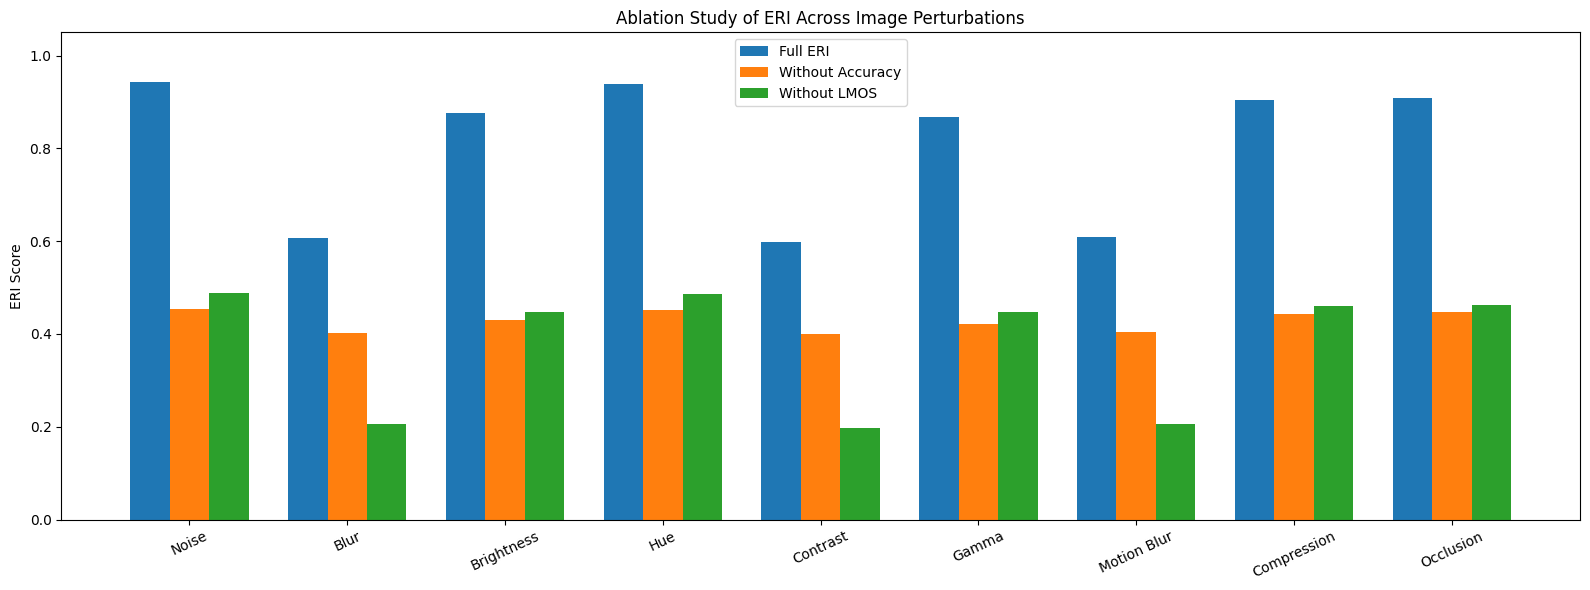

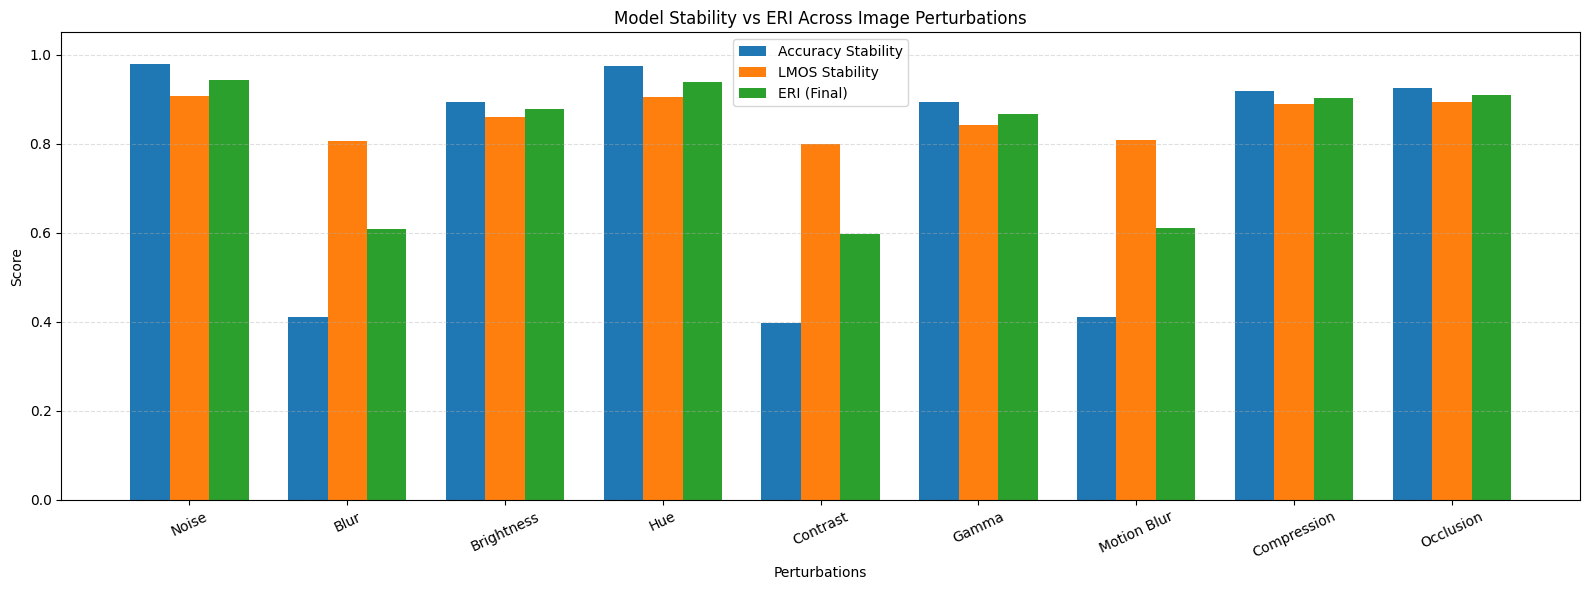

Saved: eri_components_bar.png


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================================================
# PERTURBATIONS
# ====================================================

perturbations = [
    "Noise", "Blur", "Brightness", "Hue",
    "Contrast", "Gamma", "Motion Blur",
    "Compression", "Occlusion"
]

# ====================================================
# YOUR VALUES (already computed in your code)
# ====================================================

acc_stab = [
    accuracy_stability_noise,
    accuracy_stability_blur,
    accuracy_stability_brightness,
    accuracy_stability_hue,
    accuracy_stability_contrast,
    accuracy_stability_gamma,
    accuracy_stability_motion_blur,
    accuracy_stability_compression,
    accuracy_stability_occlusion
]

lmos_stab = [
    overlap_pred_stability_noise,
    overlap_pred_stability_blur,
    overlap_pred_stability_brightness,
    overlap_pred_stability_hue,
    overlap_pred_stability_contrast,
    overlap_pred_stability_gamma,
    overlap_pred_stability_motion_blur,
    overlap_pred_stability_compression,
    overlap_pred_stability_occlusion
]

# ====================================================
# ERI COMPUTATION
# ====================================================

eri_full = [(a + l) / 2 for a, l in zip(acc_stab, lmos_stab)]
eri_no_acc = [l / 2 for l in lmos_stab]
eri_no_lmos = [a / 2 for a in acc_stab]

# ====================================================
# PRINT TABLE (IMPORTANT FOR PAPER)
# ====================================================

# ====================================================
# PRINT TABLE (IMPORTANT FOR PAPER)
# ====================================================

df = pd.DataFrame({
    "Perturbation": perturbations,
    "Accuracy_Stability": acc_stab,
    "LMOS_Stability": lmos_stab,
    "ERI_Full": eri_full,
    "ERI_No_Accuracy": eri_no_acc,
    "ERI_No_LMOS": eri_no_lmos
})

# ====================================================
# MEAN VALUES (ADDED)
# ====================================================

mean_accuracy = np.mean(acc_stab)
mean_lmos = np.mean(lmos_stab)
mean_eri = np.mean(eri_full)

print("\n================ ERI ABLATION STUDY TABLE ================\n")
print(df.to_string(index=False))

print("\n================ SUMMARY ================\n")
print(f"Mean Accuracy Stability : {mean_accuracy:.4f}")
print(f"Mean LMOS Stability     : {mean_lmos:.4f}")
print(f"Mean ERI (Full)         : {mean_eri:.4f}")
print(f"Mean ERI (No Accuracy)   : {np.mean(eri_no_acc):.4f}")
print(f"Mean ERI (No LMOS)       : {np.mean(eri_no_lmos):.4f}")
# ====================================================
# PLOT (PUBLICATION STYLE)
# ====================================================

x = np.arange(len(perturbations))
width = 0.25

plt.figure(figsize=(16,6))

bars1 = plt.bar(x - width, eri_full, width, label="Full ERI")
bars2 = plt.bar(x, eri_no_acc, width, label="Without Accuracy")
bars3 = plt.bar(x + width, eri_no_lmos, width, label="Without LMOS")

plt.xticks(x, perturbations, rotation=25)
plt.ylabel("ERI Score")
plt.title("Ablation Study of ERI Across Image Perturbations")
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.savefig("eri_ablation_study_per_perturbation_xception.png", dpi=300, bbox_inches='tight')
plt.show()



# ====================================================
# SECOND FIGURE: BAR CHART (BETTER FOR PAPER)
# ====================================================

plt.figure(figsize=(16,6))

x = np.arange(len(perturbations))
width = 0.25

plt.bar(x - width, acc_stab, width, label="Accuracy Stability")
plt.bar(x, lmos_stab, width, label="LMOS Stability")
plt.bar(x + width, eri_full, width, label="ERI (Final)")

plt.xticks(x, perturbations, rotation=25)
plt.ylabel("Score")
plt.xlabel("Perturbations")
plt.title("Model Stability vs ERI Across Image Perturbations")

plt.ylim(0, 1.05)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig(
    "eri_components_bar.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print("Saved: eri_components_bar.png")
